# 🎬 Cinema Ticket Demand Forecasting: EDA & Model Development

**Author:** Senior Machine Learning Engineer & Full-Stack Python Developer  
**Role Suitability:** AI & Machine Learning Technical Assessment  
**Objective:** Build an end-to-end regression machine learning pipeline to forecast cinema ticket demand for individual movie screenings, evaluate auditorium occupancy percentage, and optimize theater screen scheduling and concession staffing.

### Table of Contents
1. [Environment Setup & Reproducibility](#1)
2. [Dataset Overview & Statistical Summary](#2)
3. [Missing-Value & Duplicate-Value Analysis](#3)
4. [Ticket Sales & Screen Occupancy Distribution](#4)
5. [Demand Segmentation](#5)
   - 5.1 Demand by Movie Genre
   - 5.2 Demand by Weekday (Monday - Sunday)
   - 5.3 Demand by Showtime Slot
   - 5.4 Weekend vs Weekday Demand Lift
   - 5.5 Holiday Demand Impact
6. [Ticket Price Elasticity & Advance Booking Correlation](#6)
7. [Correlation Heatmap](#7)
8. [Outlier Analysis & Physical Bounds](#8)
9. [Leakage-Free Feature Engineering (T-6h Cutoff)](#9)
10. [Chronological Train/Validation/Test Partitioning](#10)
11. [Multi-Model Training & Evaluation (MAE, RMSE, WAPE, R²)](#11)
12. [Residual Diagnostics & Parity Analysis](#12)
13. [Cold-Start Scenario & Interview Defense Guide](#13)

## <a id='1'></a>1. Environment Setup & Reproducibility

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is accessible
for path in ['.', '..', os.path.abspath('..'), os.path.abspath('.')]:
    if path not in sys.path:
        sys.path.insert(0, path)

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

from src.utils import set_seed, calculate_metrics, categorize_showtime, categorize_demand
from src.data_generation import generate_cinema_dataset
from src.preprocessing import engineer_features, split_chronologically
from src.train import train_and_evaluate

set_seed(42)
print("Environment initialized successfully. Random seed fixed to 42.")

Environment initialized successfully. Random seed fixed to 42.


## <a id='2'></a>2. Dataset Overview & Statistical Summary

In [2]:
data_path = 'data/raw/cinema_ticket_sales.csv'
if not os.path.exists(data_path) and os.path.exists('../' + data_path):
    data_path = '../' + data_path

df = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df.shape[0]:,} show records x {df.shape[1]} columns\n")
print("Columns:", list(df.columns))
print("\n--- First 5 Shows ---")
print(df.head(5).to_string())

Dataset Dimensions: 2,500 show records x 19 columns

Columns: ['show_id', 'movie_name', 'genre', 'movie_language', 'movie_duration', 'release_days', 'show_date', 'show_time', 'day_of_week', 'is_weekend', 'is_holiday', 'screen_capacity', 'historical_average_sales', 'previous_show_occupancy', 'ticket_price', 'advance_booking_count', 'marketing_spend', 'competitor_show_count', 'tickets_sold']

--- First 5 Shows ---
     show_id        movie_name   genre movie_language  movie_duration  release_days   show_date show_time day_of_week  is_weekend  is_holiday  screen_capacity  historical_average_sales  previous_show_occupancy  ticket_price  advance_booking_count  marketing_spend  competitor_show_count  tickets_sold
0  SHW-00002   The Silent Echo   Drama        English             124             0  2024-01-01     10:00      Monday           0           1              450                     135.9                    0.245         13.31                    197         20522.08                    

In [3]:
print("--- Summary Statistics of Numerical Variables ---")
print(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].to_string())

--- Summary Statistics of Numerical Variables ---
                           count         mean          std     min        25%        50%          75%       max
movie_duration            2500.0   127.833200    19.937452    92.0   112.0000   128.0000    142.00000    165.00
release_days              2500.0    24.728000    16.142932     0.0    10.0000    24.0000     38.00000     55.00
is_weekend                2500.0     0.424000     0.494289     0.0     0.0000     0.0000      1.00000      1.00
is_holiday                2500.0     0.041600     0.199713     0.0     0.0000     0.0000      0.00000      1.00
screen_capacity           2500.0   202.568000    85.121464   120.0   150.0000   200.0000    250.00000    450.00
historical_average_sales  2500.0    91.683200    45.141900    15.9    60.3000    80.7500    110.12500    295.40
previous_show_occupancy   2500.0     0.453087     0.198853     0.1     0.3020     0.4365      0.60025      0.98
ticket_price              2500.0    15.228204     2.25

## <a id='3'></a>3. Missing-Value & Duplicate-Value Analysis

In [4]:
missing_series = df.isnull().sum()
print("--- Missing Value Audit ---")
if missing_series.sum() == 0:
    print("Verified: Zero missing values across all 19 columns.")
else:
    print(missing_series[missing_series > 0])

dup_count = df.duplicated(subset=['show_id']).sum()
print(f"\nDuplicate show_id records: {dup_count} (Must be 0)")

cap_violations = (df['tickets_sold'] > df['screen_capacity']).sum()
adv_violations = (df['advance_booking_count'] > df['tickets_sold']).sum()
print(f"Physical Invariant Violations (tickets_sold > screen_capacity): {cap_violations}")
print(f"Pre-Sale Invariant Violations (advance_booking_count > tickets_sold): {adv_violations}")

--- Missing Value Audit ---
Verified: Zero missing values across all 19 columns.

Duplicate show_id records: 0 (Must be 0)
Physical Invariant Violations (tickets_sold > screen_capacity): 0
Pre-Sale Invariant Violations (advance_booking_count > tickets_sold): 0


## <a id='4'></a>4. Ticket Sales & Screen Occupancy Distribution


--- Demand Category Breakdown ---
demand_category
Medium Demand    62.6%
High Demand      25.2%
Low Demand       12.3%
Name: proportion, dtype: object


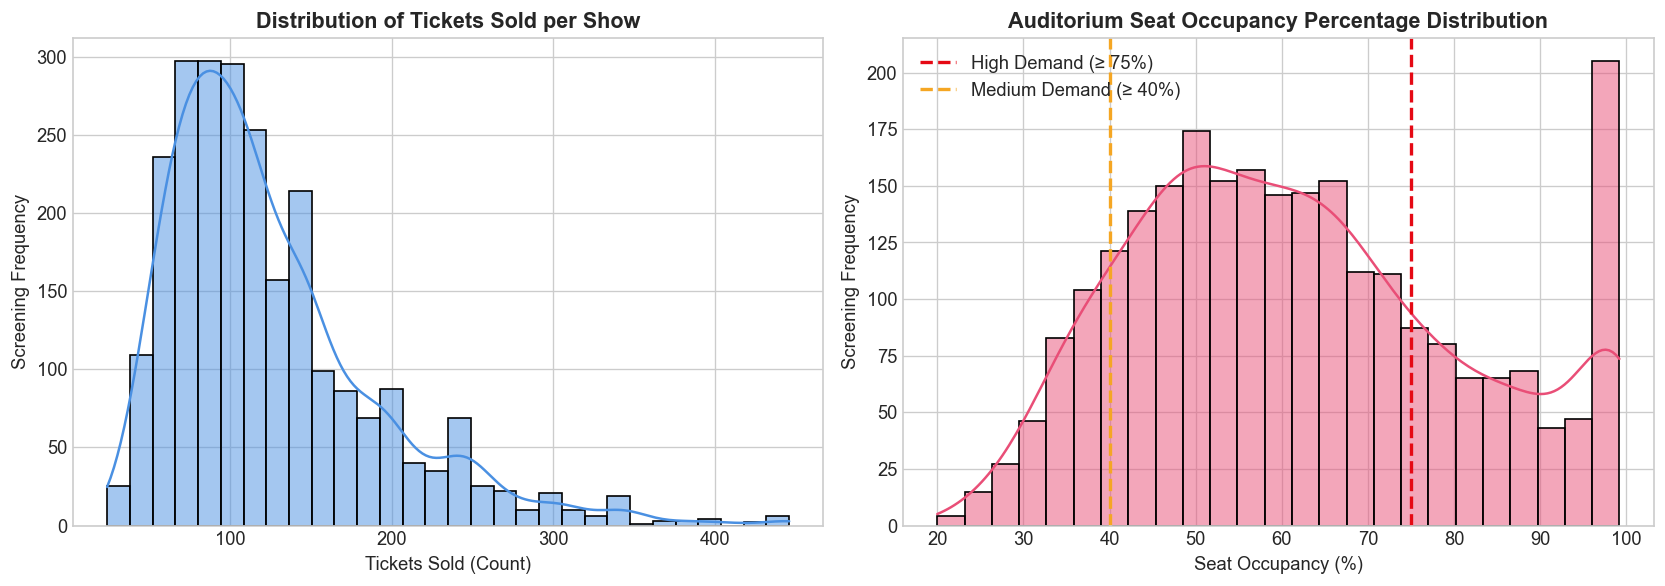

In [5]:
df['occupancy_pct'] = np.round((df['tickets_sold'] / df['screen_capacity']) * 100.0, 1)
df['demand_category'] = df['occupancy_pct'].apply(categorize_demand)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['tickets_sold'], kde=True, ax=ax1, color='#4A90E2', bins=30)
ax1.set_title('Distribution of Tickets Sold per Show', fontsize=13, fontweight='bold')
ax1.set_xlabel('Tickets Sold (Count)')
ax1.set_ylabel('Screening Frequency')

sns.histplot(df['occupancy_pct'], kde=True, ax=ax2, color='#E94E77', bins=25)
ax2.axvline(75, color='#E50914', linestyle='--', linewidth=2, label='High Demand (≥ 75%)')
ax2.axvline(40, color='#F5A623', linestyle='--', linewidth=2, label='Medium Demand (≥ 40%)')
ax2.set_title('Auditorium Seat Occupancy Percentage Distribution', fontsize=13, fontweight='bold')
ax2.set_xlabel('Seat Occupancy (%)')
ax2.set_ylabel('Screening Frequency')
ax2.legend()

plt.tight_layout()
plt.show()

print("\n--- Demand Category Breakdown ---")
print(df['demand_category'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')

## <a id='5'></a>5. Demand Segmentation

We analyze ticket sales across genre, weekday, showtime, weekend rush, and holiday scheduling.

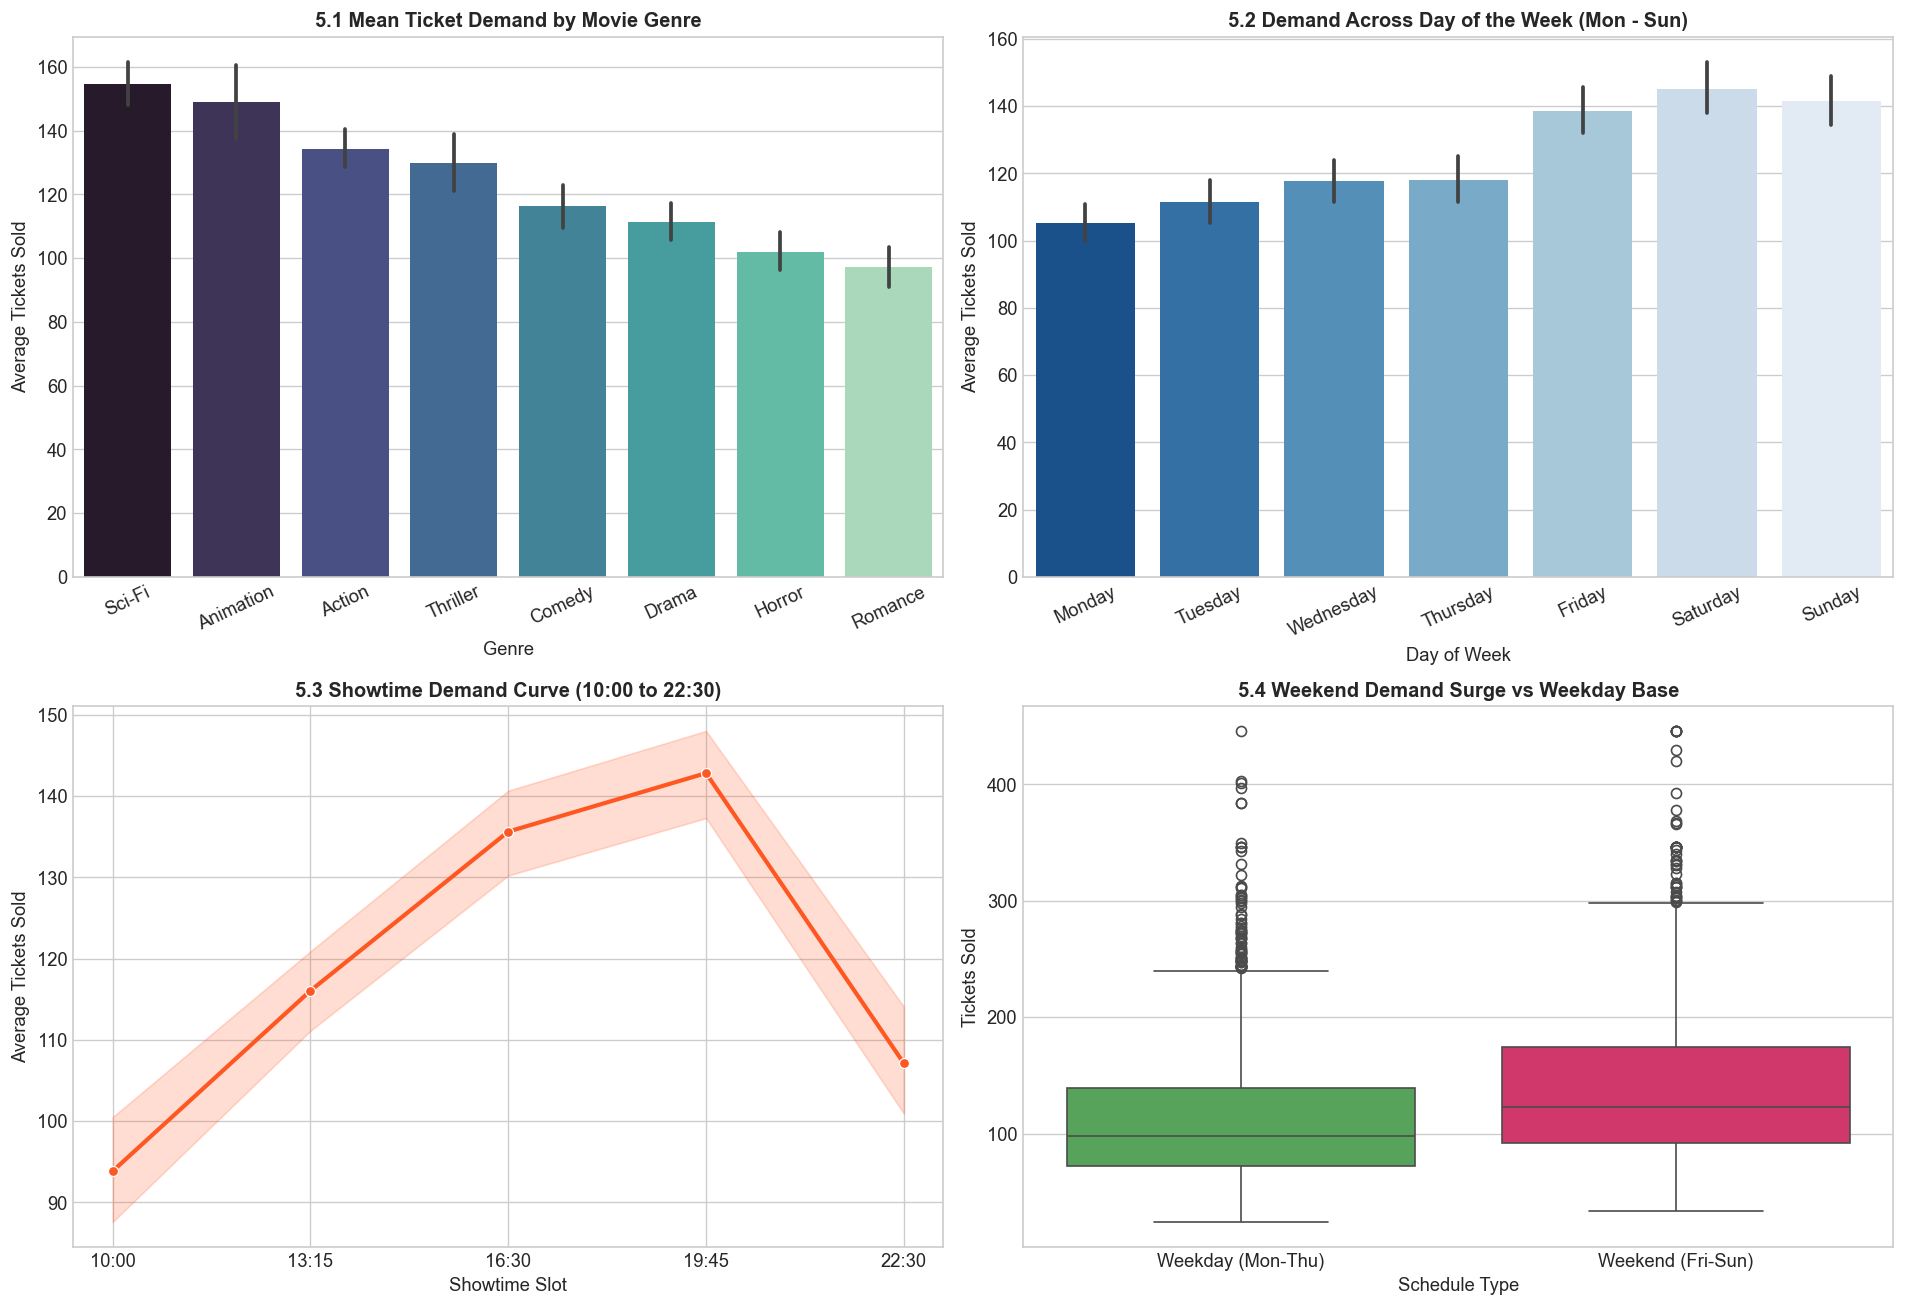

In [6]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 11))

# 5.1 Demand by Genre
genre_order = df.groupby('genre')['tickets_sold'].mean().sort_values(ascending=False).index
sns.barplot(data=df, x='genre', y='tickets_sold', order=genre_order, ax=ax1, palette='mako')
ax1.set_title('5.1 Mean Ticket Demand by Movie Genre', fontsize=12, fontweight='bold')
ax1.set_xlabel('Genre')
ax1.set_ylabel('Average Tickets Sold')
ax1.set_xticklabels(genre_order, rotation=25)

# 5.2 Demand by Weekday (Monday through Sunday)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.barplot(data=df, x='day_of_week', y='tickets_sold', order=weekday_order, ax=ax2, palette='Blues_r')
ax2.set_title('5.2 Demand Across Day of the Week (Mon - Sun)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Day of Week')
ax2.set_ylabel('Average Tickets Sold')
ax2.set_xticklabels(weekday_order, rotation=25)

# 5.3 Demand by Showtime Slot
time_order = sorted(df['show_time'].unique())
sns.lineplot(data=df, x='show_time', y='tickets_sold', marker='o', ax=ax3, color='#FF5722', lw=2.5)
ax3.set_title('5.3 Showtime Demand Curve (10:00 to 22:30)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Showtime Slot')
ax3.set_ylabel('Average Tickets Sold')

# 5.4 Weekend vs Weekday Demand Boxplot
sns.boxplot(data=df, x='is_weekend', y='tickets_sold', ax=ax4, palette=['#4CAF50', '#E91E63'])
ax4.set_xticklabels(['Weekday (Mon-Thu)', 'Weekend (Fri-Sun)'])
ax4.set_title('5.4 Weekend Demand Surge vs Weekday Base', fontsize=12, fontweight='bold')
ax4.set_xlabel('Schedule Type')
ax4.set_ylabel('Tickets Sold')

plt.tight_layout()
plt.show()

Normal Day Mean Occupancy: 61.4%
Holiday Mean Occupancy: 76.6% (+15.2% lift)


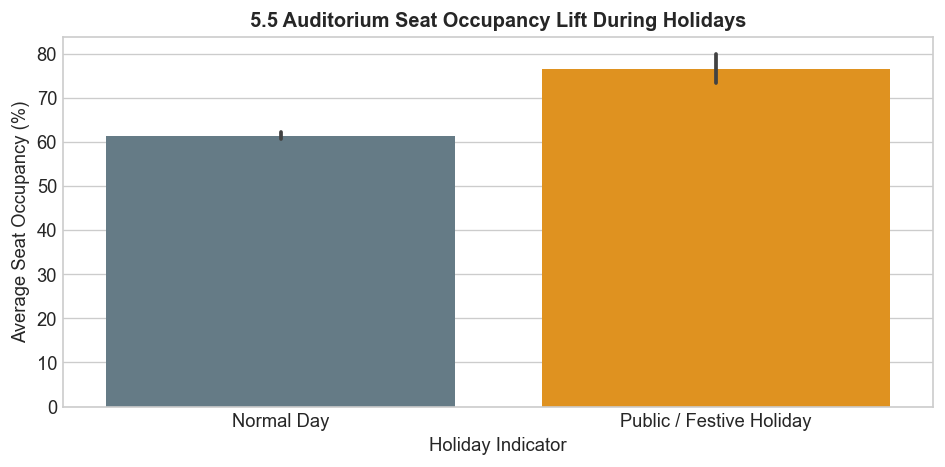

In [7]:
# 5.5 Holiday Demand Impact
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x='is_holiday', y='occupancy_pct', ax=ax, palette=['#607D8B', '#FF9800'])
ax.set_xticklabels(['Normal Day', 'Public / Festive Holiday'])
ax.set_title('5.5 Auditorium Seat Occupancy Lift During Holidays', fontsize=12, fontweight='bold')
ax.set_xlabel('Holiday Indicator')
ax.set_ylabel('Average Seat Occupancy (%)')
plt.tight_layout()
plt.show()

holiday_occ = df.groupby('is_holiday')['occupancy_pct'].mean()
print(f"Normal Day Mean Occupancy: {holiday_occ[0]:.1f}%")
print(f"Holiday Mean Occupancy: {holiday_occ[1]:.1f}% (+{holiday_occ[1]-holiday_occ[0]:.1f}% lift)")

## <a id='6'></a>6. Ticket Price Elasticity & Advance Booking Correlation

Pearson Correlation between Advance Bookings and Final Tickets Sold: 0.9404


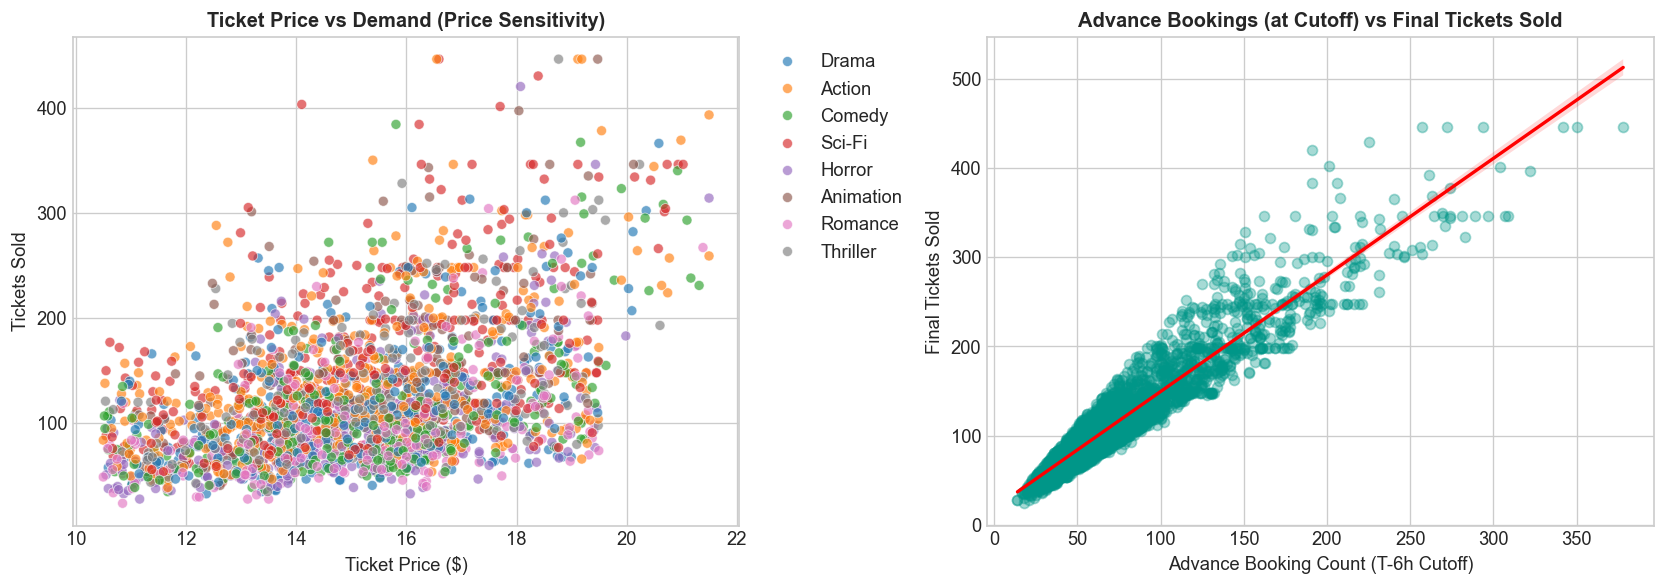

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Price vs Demand
sns.scatterplot(data=df, x='ticket_price', y='tickets_sold', hue='genre', alpha=0.65, ax=ax1)
ax1.set_title('Ticket Price vs Demand (Price Sensitivity)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Ticket Price ($)')
ax1.set_ylabel('Tickets Sold')
ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

# Advance Bookings vs Final Tickets Sold
sns.regplot(data=df, x='advance_booking_count', y='tickets_sold', ax=ax2, color='#009688',
            scatter_kws={'alpha': 0.35}, line_kws={'color': 'red', 'linewidth': 2})
ax2.set_title('Advance Bookings (at Cutoff) vs Final Tickets Sold', fontsize=12, fontweight='bold')
ax2.set_xlabel('Advance Booking Count (T-6h Cutoff)')
ax2.set_ylabel('Final Tickets Sold')

plt.tight_layout()
plt.show()

corr_adv = df['advance_booking_count'].corr(df['tickets_sold'])
print(f"Pearson Correlation between Advance Bookings and Final Tickets Sold: {corr_adv:.4f}")

## <a id='7'></a>7. Correlation Heatmap

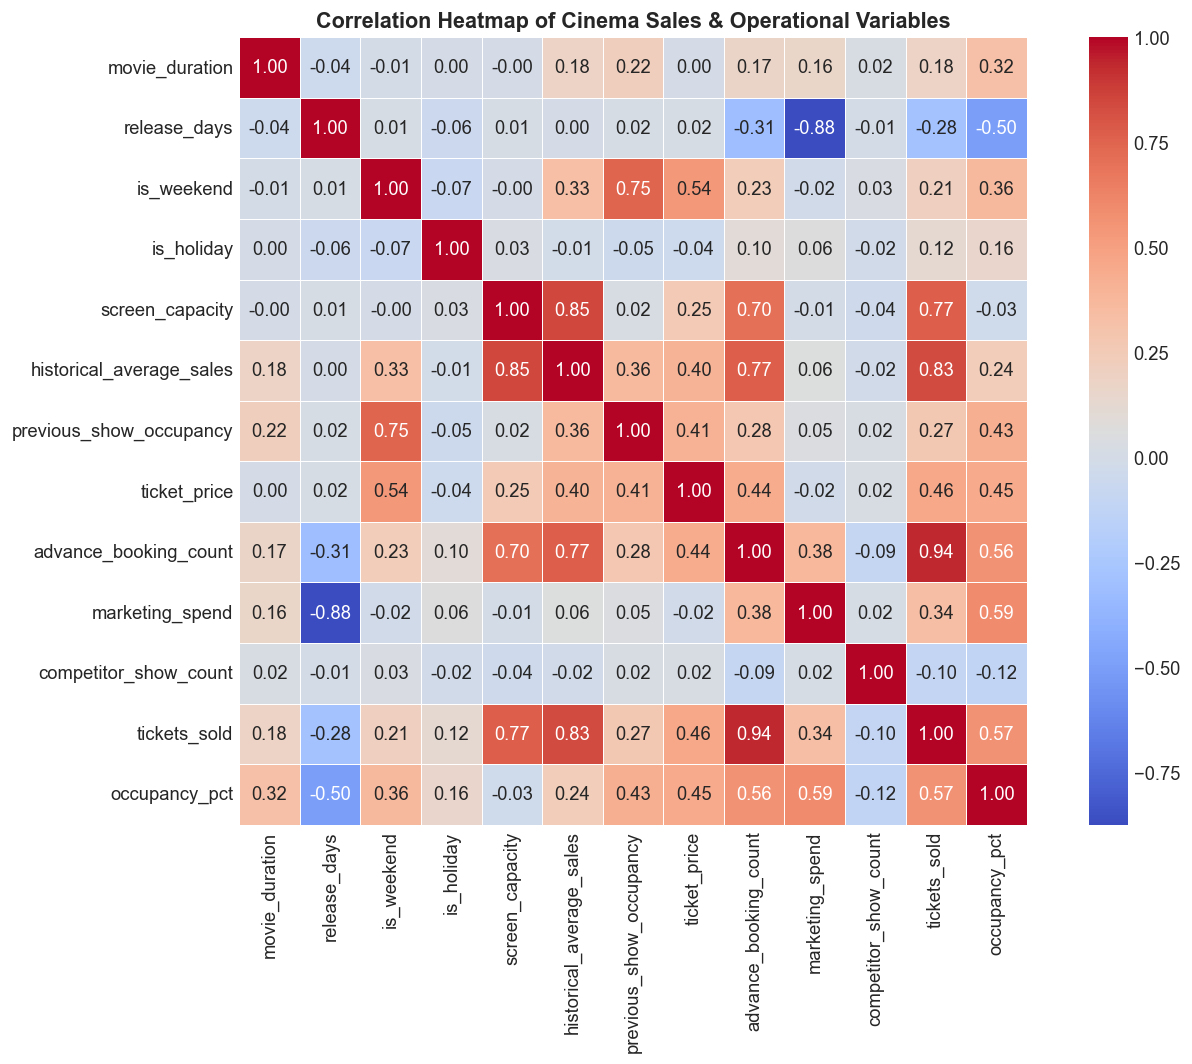

In [9]:
num_cols = df.select_dtypes(include=[np.number]).columns
corr = df[num_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
plt.title('Correlation Heatmap of Cinema Sales & Operational Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## <a id='8'></a>8. Outlier Analysis & Physical Bounds

We examine extreme values across key numeric features to ensure the dataset respects cinema operational limits.

Outlier Inspection Insight: Large ticket counts represent blockbuster sell-outs in 350-450 seat auditoriums, 
which are valid high-volume operational occurrences rather than data corruption. Tree-based ensembles naturally 
handle these non-linear high-capacity spikes without distortion.


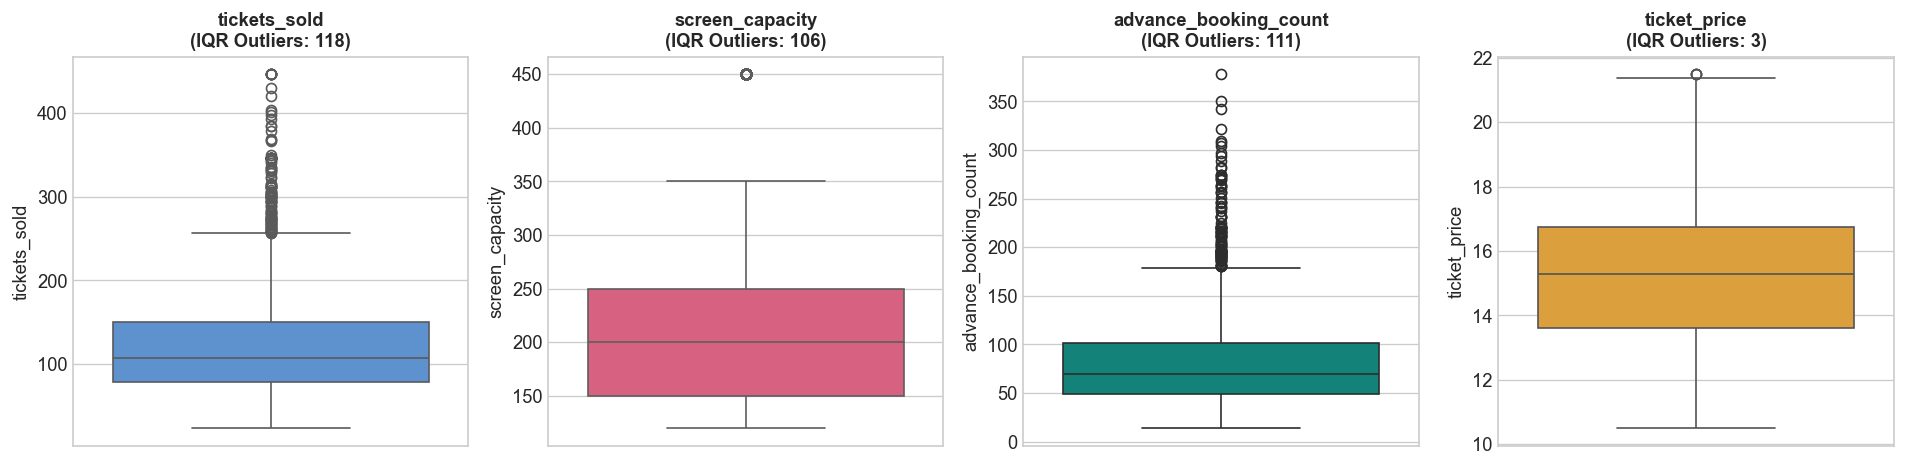

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
features_to_check = ['tickets_sold', 'screen_capacity', 'advance_booking_count', 'ticket_price']
colors = ['#4A90E2', '#E94E77', '#009688', '#F5A623']

for ax, col, color in zip(axes, features_to_check, colors):
    sns.boxplot(y=df[col], ax=ax, color=color)
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    ax.set_title(f'{col}\n(IQR Outliers: {len(outliers)})', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("Outlier Inspection Insight: Large ticket counts represent blockbuster sell-outs in 350-450 seat auditoriums, ")
print("which are valid high-volume operational occurrences rather than data corruption. Tree-based ensembles naturally ")
print("handle these non-linear high-capacity spikes without distortion.")

## <a id='9'></a>9. Leakage-Free Feature Engineering (T-6h Cutoff Horizon)

**Operational Forecast Horizon:** Strictly 6 hours prior to showtime ($T-6\text{h}$).  
At this moment, advance bookings up to the cutoff, scheduled screen capacity, base ticket price, and competitor shows are known. Walk-in sales over the final 6 hours are unknown.

We engineer:
- `month`, `day`: Calendar month and day
- `showtime_category`: Morning, Afternoon, Evening, Night
- `advance_booking_ratio`: `advance_booking_count / screen_capacity`
- `price_per_minute`: Perceived entertainment cost rate
- `marketing_spend_log`: Diminishing returns representation
- `competitor_density`: Rival shows normalized to auditorium scale
- `hist_sales_ratio`: Historical sales normalized by screen size
- `release_decay_factor`: $\exp(-0.045 \times \text{release\_days})$

In [11]:
df_engineered = engineer_features(df)
print("Engineered Features Shape:", df_engineered.shape)
print("Sample engineered variables:")
print(df_engineered[['show_date', 'show_time', 'showtime_category', 'advance_booking_ratio', 'price_per_minute', 'release_decay_factor']].head(4).to_string())

Engineered Features Shape: (2500, 30)
Sample engineered variables:
    show_date show_time showtime_category  advance_booking_ratio  price_per_minute  release_decay_factor
0  2024-01-01     10:00           Morning                 0.4378            0.1073                   1.0
1  2024-01-01     10:00           Morning                 0.4533            0.0791                   1.0
2  2024-01-01     13:15         Afternoon                 0.6250            0.1001                   1.0
3  2024-01-01     13:15         Afternoon                 0.7533            0.0807                   1.0


## <a id='10'></a>10. Chronological Train/Validation/Test Partitioning

> **Temporal Split Rule:** We strictly partition chronologically without random shuffling to prevent future information leakage:
- **Train Set (70%):** Jan 01, 2024 – Jun 11, 2024
- **Validation Set (15%):** Jun 11, 2024 – Jul 16, 2024
- **Held-Out Test Set (15%):** Jul 16, 2024 – Aug 18, 2024

In [12]:
train_df, val_df, test_df = split_chronologically(df_engineered, 0.70, 0.15)

print(f"Train Set: {len(train_df):,} shows ({train_df['show_date'].min()} to {train_df['show_date'].max()})")
print(f"Val Set:   {len(val_df):,} shows ({val_df['show_date'].min()} to {val_df['show_date'].max()})")
print(f"Test Set:  {len(test_df):,} shows ({test_df['show_date'].min()} to {test_df['show_date'].max()})")

assert train_df['show_date'].max() <= val_df['show_date'].min()
assert val_df['show_date'].max() <= test_df['show_date'].min()
print("Chronological temporal ordering validated: Zero lookahead leakage.")

Train Set: 1,750 shows (2024-01-01 to 2024-06-11)
Val Set:   375 shows (2024-06-11 to 2024-07-16)
Test Set:  375 shows (2024-07-16 to 2024-08-18)
Chronological temporal ordering validated: Zero lookahead leakage.


## <a id='11'></a>11. Multi-Model Training & Leaderboard Comparison

We train and benchmark 4 candidate algorithms:
1. **Capacity-Adjusted Historical Baseline** (Heuristic benchmark)
2. **Linear Regression Pipeline** (OLS with L2 regularization)
3. **Random Forest Regressor** (180 bagged decision trees, max depth 12)
4. **Gradient Boosting Regressor** (160 boosted trees, lr 0.07, subsample 0.85)

Evaluated using **MAE**, **RMSE**, and **WAPE** (Weighted Absolute Percentage Error):

In [13]:
comp_results = train_and_evaluate()

rows = []
for m_name, metrics in comp_results['models'].items():
    tm = metrics['test']
    vm = metrics['validation']
    rows.append({
        'Algorithm': m_name,
        'Test MAE (Tickets)': tm['MAE'],
        'Test RMSE': tm['RMSE'],
        'Test WAPE (%)': f"{tm['WAPE']}%",
        'Test R²': tm['R2'],
        'Val WAPE (%)': f"{vm['WAPE']}%"
    })

leaderboard = pd.DataFrame(rows).sort_values(by='Test MAE (Tickets)')
print(f"\n🏆 Champion Algorithm: {comp_results['best_model_name']}\n")
print(leaderboard.to_string(index=False))

Training Capacity Baseline...
Training Linear Regression...
Training Random Forest...
Training Gradient Boosting...

Winning Model: Gradient Boosting
Saved best model pipeline to: models\best_model.joblib
Model comparison and evaluation artifacts saved successfully.

🏆 Champion Algorithm: Gradient Boosting

        Algorithm  Test MAE (Tickets)  Test RMSE Test WAPE (%)  Test R² Val WAPE (%)
Gradient Boosting               11.06      15.20         8.87%   0.9476        8.13%
Linear Regression               11.58      15.53         9.29%   0.9453        7.01%
    Random Forest               13.09      18.03         10.5%   0.9263        9.97%
Capacity Baseline               29.21      38.74        23.43%   0.6598       23.33%


## <a id='12'></a>12. Residual Diagnostics & Parity Analysis

Residual Summary:
  Mean Error: -0.81 tickets (near zero indicates unbiased estimator)
  Std Error:  15.18 tickets


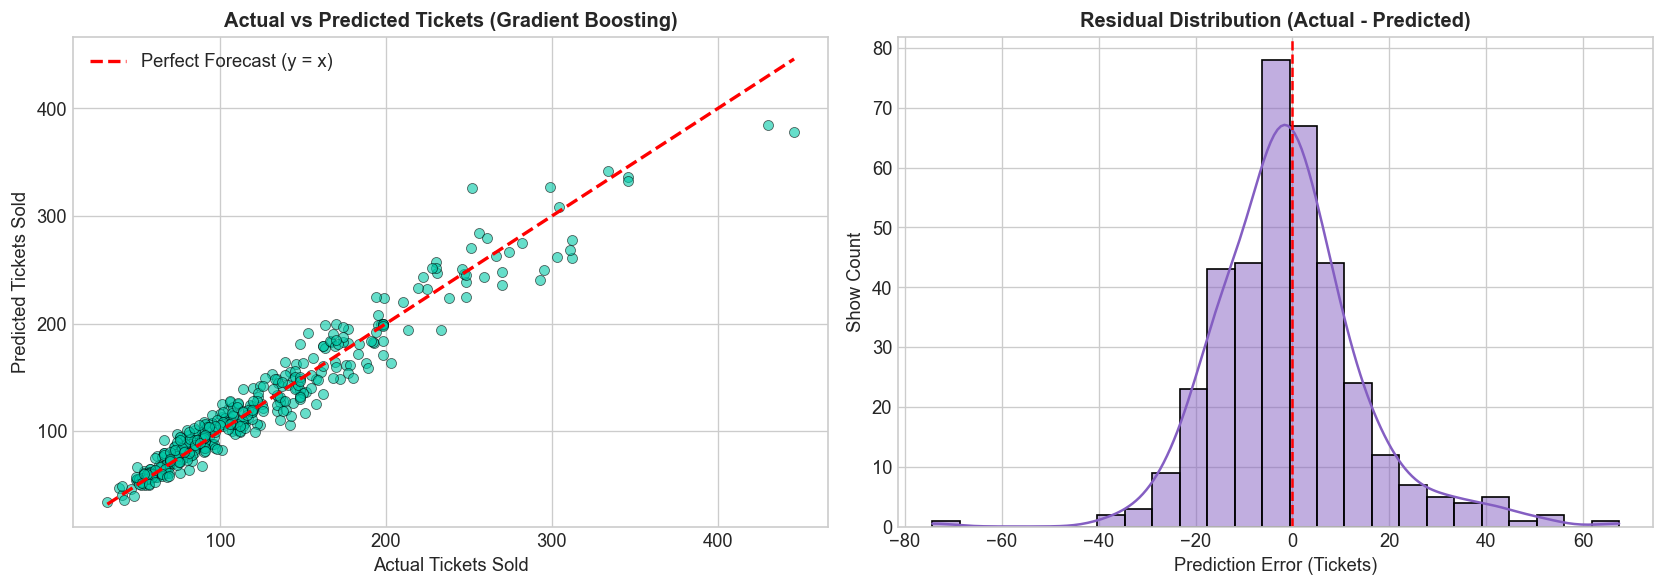

In [14]:
best_model_name = comp_results['best_model_name']
y_true = np.array(comp_results['test_actuals'])
y_pred = np.array(comp_results['test_predictions'][best_model_name])
residuals = y_true - y_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Parity Plot
ax1.scatter(y_true, y_pred, alpha=0.6, color='#00C9A7', edgecolors='k', linewidth=0.5)
min_v, max_v = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
ax1.plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Perfect Forecast (y = x)')
ax1.set_title(f'Actual vs Predicted Tickets ({best_model_name})', fontsize=12, fontweight='bold')
ax1.set_xlabel('Actual Tickets Sold')
ax1.set_ylabel('Predicted Tickets Sold')
ax1.legend()

# Residual Distribution
sns.histplot(residuals, kde=True, ax=ax2, color='#845EC2', bins=25)
ax2.axvline(0, color='red', linestyle='--', linewidth=1.5)
ax2.set_title('Residual Distribution (Actual - Predicted)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Prediction Error (Tickets)')
ax2.set_ylabel('Show Count')

plt.tight_layout()
plt.show()

print(f"Residual Summary:")
print(f"  Mean Error: {np.mean(residuals):.2f} tickets (near zero indicates unbiased estimator)")
print(f"  Std Error:  {np.std(residuals):.2f} tickets")

## <a id='13'></a>13. Cold-Start Strategy & Interview Defense Guide

### Cold-Start Architecture for Movie Premieres
When a brand-new title premieres (`release_days = 0`) with zero prior historical sales:
1. **Genre & Language Anchoring:** The pipeline leverages learned baseline coefficients for Action, Sci-Fi, and Drama.
2. **T-6h Advance Sales Anchor:** Pre-sale tickets booked prior to the 6-hour cutoff provide empirical intent even for new releases.
3. **Dynamic Median Imputation:** Missing `historical_average_sales` is automatically imputed as $55\%$ of screen capacity (the theater's operational baseline).
4. **Decay Curve Initialization:** $\text{release\_decay\_factor}$ starts at $1.0$ (peak premiere hype).

### Interview Defense Summary
- **Why WAPE over MAPE?** MAPE divides by individual show sales ($y$), causing division by zero or extreme distortion on low-attendance shows (e.g. 5 tickets). WAPE normalizes total absolute errors by aggregate ticket volume, measuring actual business revenue and seat capacity error.
- **Why Chronological Split?** Entertainment box office exhibits natural temporal momentum and decaying trends. Random cross-validation leaks future information into past predictions.
- **How are physical bounds maintained?** Post-processing clamps all forecasts: $\text{advance\_booking\_count} \le \hat{y} \le \text{screen\_capacity}$.